# Graduated S-SZD

In [1]:
import torch

from eszd import GSSZD, ESZD, Optimizer
from eszd.directions import FastRandomCoords, HouseholderQRDirections
from math import exp, pi, sqrt, log
import matplotlib.pyplot as plt

In [2]:
a = 20.0
b = 0.2
c = 2 * pi
def ackley_1d(x):
    t1 = -a * torch.exp(-b * torch.sqrt(x.square().mean(dim=1, keepdim=True)))
    t2 = -torch.exp(torch.cos(x * c).mean(dim=1, keepdim=True))
    noise = torch.randn((x.shape[0], 1))
    return t1 + t2 + a + exp(1) #+ noise

torch.Size([1000])


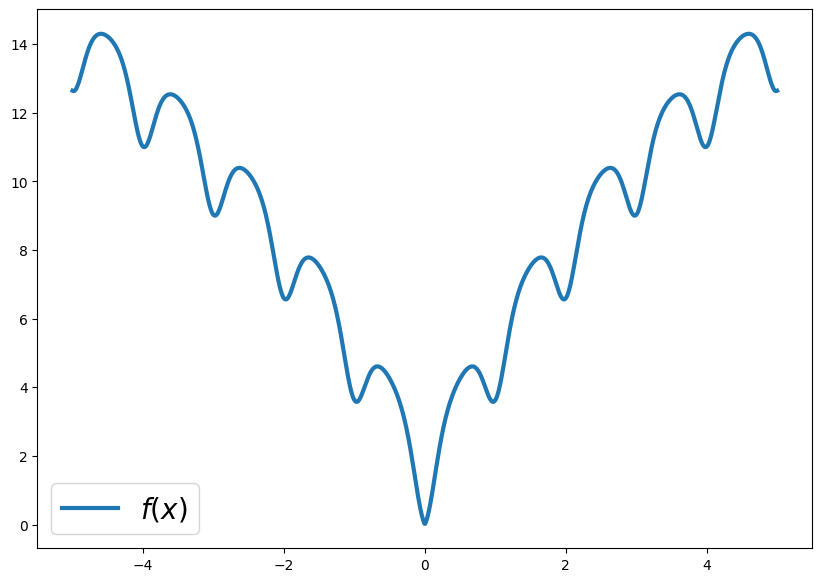

In [4]:
X = torch.linspace(-5, 5, 1000).reshape(-1, 1)

print(X.mean(1).shape)
Y = ackley_1d(X)


fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(X, Y, '-', lw=3, label='$f(x)$')
ax.legend(fontsize=20)
fig.savefig("./ackley_prob.pdf", bbox_inches='tight')

torch.Size([1000])


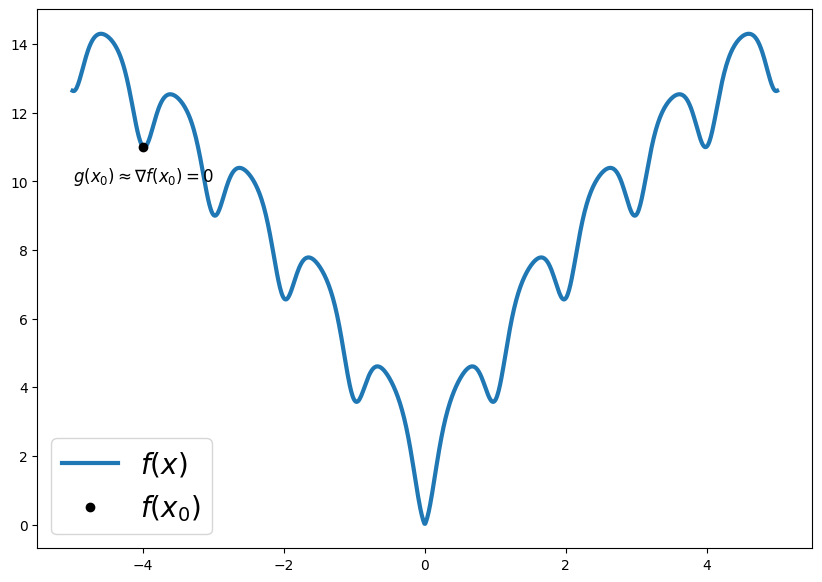

In [23]:
X = torch.linspace(-5, 5, 1000).reshape(-1, 1)

print(X.mean(1).shape)
Y = ackley_1d(X)

x0 =torch.tensor([[-4.]])
y0 = ackley_1d(x0)

fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(X, Y, '-', lw=3, label='$f(x)$')
ax.plot(x0, y0, 'o', c='black', label='$f(x_0)$')

ax.text(-5., 10., '$g(x_0) \\approx \\nabla f(x_0) =  0 $', fontdict={'fontsize' : 12})
ax.legend(fontsize=20)
fig.savefig("./ackley_sszd.pdf", bbox_inches='tight')

In [30]:
gen = torch.Generator()

gen.manual_seed(12)

def smt_ackley1(x, h = 1000.0):
    p = torch.randn(x.shape, generator=gen)
#    p /= p.norm()# torch.rand(x.shape) * (p/p.norm(dim=0))
#    p *= torch.rand(1)#x.shape)
    return ackley_1d(x + h * p)
    
    #X = torch.linspace(-20, 20, 1000).reshape(-1, 1)

h_vals = [0.1, 0.2, 0.3, 0.5, 1.0, 2.0, 5.0, 10.0]
    
for h in h_vals:
    Ysmt = []
    for _ in range(1000):
        y = smt_ackley1(X, h=h).numpy()
        Ysmt.append(y)#.flatten()

    import numpy as np

    Ysmt = np.mean(Ysmt, 0)
    #print(Ysmt)
    #Ysmt = Ysmt.flatten()

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.plot(X, Y, '-', lw=3, label='$f(x)$')
    ax.plot(X, Ysmt, '-', lw=3, label='$f_h(x)$')
    ax.legend(fontsize=20)
    plt.savefig("./smoothing_{}.pdf".format(h), bbox_inches='tight')
    plt.close(fig)

In [652]:
class SimulatedAnnealing:
    def __init__(self, target, x, T, max_iters = 10, budget = 100, stepsize=1.0, seed=12) -> None:
        self.target = target
        self.x = x
        self.stepsize = stepsize
        self.T = T
        self.k = 1
        self.generator = torch.Generator()
        self.generator.manual_seed(seed)
        def sampler(x):
            inc = torch.randn(x.shape, generator=self.generator)*self.stepsize
            xn = self.x + inc
            return xn
#            return torch.clamp(,
#                               min=torch.full(self.x.shape, -20.0),
#                               max=torch.full(self.x.shape, 25.0))
                               
        self.sampler = sampler
        self.budget = budget
        self.tot_evals = 0
        self.max_iters = max_iters

    def _minimize_inner(self):
        fx = self.target(self.x)
        T = self.T(self.k)
        num_evals = 1
        self.tot_evals+=1
        t = 0
        while t < self.max_iters and self.tot_evals < self.budget:
            x_n = self.sampler(self.x)
            f_n = self.target(x_n)
            delta = f_n - fx
            if torch.rand(1, generator=self.generator).item() < min([torch.exp(-delta/T).item(), 1.0]):
                self.x = x_n
                fx = self.target(x_n)
                num_evals+=1
                self.tot_evals+=1
            num_evals+=1
            self.tot_evals+=1
            t+=1
        return num_evals
            
            
    def step(self):
        num_evals = self._minimize_inner()
        self.k +=1
        return self.x, num_evals         
    
    

In [845]:
class GradOpt:
    def __init__(self, target, x, h, alpha, theta=0.5, 
                 max_iters = 10, budget = 100, seed=12) -> None:
        self.target = target
        self.x = x
        self.alpha = alpha
        self.h = h
        self.h_min = torch.finfo(x.dtype).eps
        self.theta = theta
        self.k = 1
        self.generator = torch.Generator()
        self.generator.manual_seed(seed)
        def sampler():
            h = max(self.h, self.h_min)
            fx = self.target(self.x)
            p = torch.randn(self.x.shape, generator=self.generator)
            p/=p.norm()
            xn = ((self.target(self.x + h * p) -fx)/h) * p
            return xn
                               
        self.sampler = sampler
        self.budget = budget
        self.tot_evals = 0
        self.max_iters = max_iters

    def _minimize_inner(self):
        num_evals = 1
        self.tot_evals+=1
        t = 0
        
        while t < self.max_iters and self.tot_evals < self.budget:
            g = self.sampler()
            
            self.x = self.x - self.alpha(t + 1) * self.h * g
            num_evals+=2
            self.tot_evals+=2
            t+=1
        return num_evals
            
            
    def step(self):
        num_evals = self._minimize_inner()
        self.k +=1
        self.h*=self.theta
        return self.x, num_evals         
    
    

In [866]:
d = 50
l = d
dtype = torch.float64
device = 'cpu'
P = HouseholderQRDirections(d = d, l = l, dtype=dtype, device=device)

alpha = lambda k :  1.0 * (1/sqrt(k)) * l/d
init_h = 30.0
x0 = torch.full((1, d), 10.0, dtype=dtype, device=device)
budget = 20000

gopt = GradOpt(target=ackley_1d,
               x = x0.clone(),
               h=30.0,
               alpha=lambda t: 2/sqrt(t),
               theta=0.995,
               max_iters=10,
               budget=budget
               )
sa_opt = SimulatedAnnealing(target=ackley_1d,
                            x = x0.clone(),
                            T = lambda t : 5/t, #5 * log(t+1)/t,
                            budget=budget,
                            stepsize=1.02,
                            max_iters=1
                            )

opt = GSSZD(target = ackley_1d, 
            x=x0, 
            P=P,
            alpha = lambda t : 2.0/sqrt(t),
            init_h = init_h,
            eps=1e-3,
            theta = 0.6,
            max_iters = 10,
            budget = budget,
            verbose=False
           )
opt2 = ESZD(target = ackley_1d, 
            x=x0.clone(), 
            P=P,
            alpha =alpha,
            h = lambda t: 1e-7,
            verbose=False
           )


In [861]:
ext_evals2 = [opt2.target(opt2.x).item()]
i = 0
while opt2.f_evals < budget:
    x = opt2.step()
    fx = opt2.target(x).item()
#    print("[i={}] x: {}\tfx: {}".format(i, x.item(), round(fx, 4)))
    ext_evals2 += [fx for _ in range(opt2.l + 1)] #.append(fx)
    i+=1


In [862]:
ext_evals_sa = [sa_opt.target(x0).item()]
i = 0
nevs = []
while sa_opt.tot_evals < budget:
    x, n_eval = sa_opt.step()
    fx = sa_opt.target(x).item()
   # print("[i={}] fx: {}".format(i, round(fx, 4)))
    ext_evals_sa += [fx for _ in range(n_eval)] #.append(fx)
    nevs.append(n_eval)
    i+=1


In [867]:
ext_evals_go = [gopt.target(x0).item()]
i = 0
nevs = []
while gopt.tot_evals < budget:
    x, n_eval = gopt.step()
    fx = gopt.target(x).item()
    print("[i={}] fx: {}\th: {}".format(i, round(fx, 4), gopt.h))
    ext_evals_go += [fx for _ in range(n_eval)] #.append(fx)
    nevs.append(n_eval)
    i+=1


[i=0] fx: 18.9859	h: 29.85
[i=1] fx: 18.8918	h: 29.700750000000003
[i=2] fx: 18.9988	h: 29.552246250000003
[i=3] fx: 19.0236	h: 29.40448501875
[i=4] fx: 19.086	h: 29.257462593656253
[i=5] fx: 18.9888	h: 29.111175280687974
[i=6] fx: 18.9267	h: 28.965619404284535
[i=7] fx: 18.7368	h: 28.82079130726311
[i=8] fx: 18.8431	h: 28.676687350726795
[i=9] fx: 18.8399	h: 28.53330391397316
[i=10] fx: 18.7957	h: 28.390637394403296
[i=11] fx: 18.8101	h: 28.24868420743128
[i=12] fx: 18.7724	h: 28.107440786394122
[i=13] fx: 18.6743	h: 27.96690358246215
[i=14] fx: 18.5629	h: 27.82706906454984
[i=15] fx: 18.6396	h: 27.68793371922709
[i=16] fx: 18.5608	h: 27.549494050630955
[i=17] fx: 18.4964	h: 27.411746580377798
[i=18] fx: 18.576	h: 27.27468784747591
[i=19] fx: 18.6354	h: 27.13831440823853
[i=20] fx: 18.4399	h: 27.002622836197336
[i=21] fx: 18.6064	h: 26.86760972201635
[i=22] fx: 18.3519	h: 26.733271673406268
[i=23] fx: 18.4663	h: 26.599605315039238
[i=24] fx: 18.3567	h: 26.46660728846404
[i=25] fx: 18.

In [868]:
ext_evals = [opt.target(x0).item()]
i = 0
nevs = []
while opt.f_evals < budget:
    x, n_eval = opt.step()
    fx = opt.target(x).item()
#    print("[i={}] x: {}\tfx: {}\th: {}".format(i, x.numpy(), round(fx, 4), opt.h))
    ext_evals += [fx for _ in range(n_eval)] #.append(fx)
    nevs.append(n_eval)
    i+=1


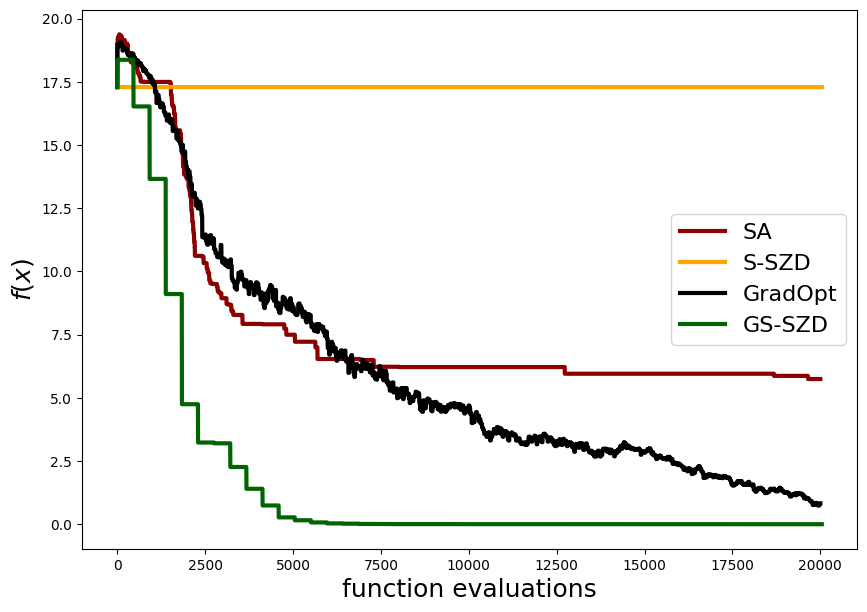

In [872]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(range(len(ext_evals_sa)), ext_evals_sa, '-', c='darkred', lw=3, label='SA')
ax.plot(range(len(ext_evals2)), ext_evals2, '-', c='orange', lw=3, label='S-SZD')
ax.plot(range(len(ext_evals_go)), ext_evals_go, '-', c='black', lw=3, label='GradOpt')
ax.plot(range(len(ext_evals)), ext_evals, '-', c='darkgreen', lw=3, label='GS-SZD')
ax.legend(fontsize=16)
ax.set_xlabel("function evaluations", fontsize=18)
ax.set_ylabel("$f(x)$", fontsize=18)
#ax.set_yscale("log")
fig.savefig("ackley50_comp.pdf", bbox_inches='tight')


In [36]:

class GSSZDLS(GSSZD):
    def __init__(self, 
                 eps : float = 1e-5, 
                 theta : float = 0.5,
                 rho : float = 10.0,
                 init_h : float = 1e-3,
                 max_iters : int = 100,
                 budget : int | None = None, 
                 h_min : float | None = None,
                 **kwargs):
        self.eps = eps
        self.theta = theta
        self.rho = rho
        self.init_h = init_h
        self.max_iters = max_iters
        self.h = init_h
        self.budget = budget
        self.h_min = torch.finfo(self.x.dtype).eps if h_min is None else h_min
        self.t = 1
        
    def step(self, x):
        Pk = self.P()
        alpha = self.alpha(self.t)
        h = max(self.h / self.t , self.h_min)
        g = self.
        
        self.t += 1
    